# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [11]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [12]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [13]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np

Количество коэффициентов близких к 0 (Lasso): 7 из 10
Количество коэффициентов близких к 0 (Ridge): 0 из 10


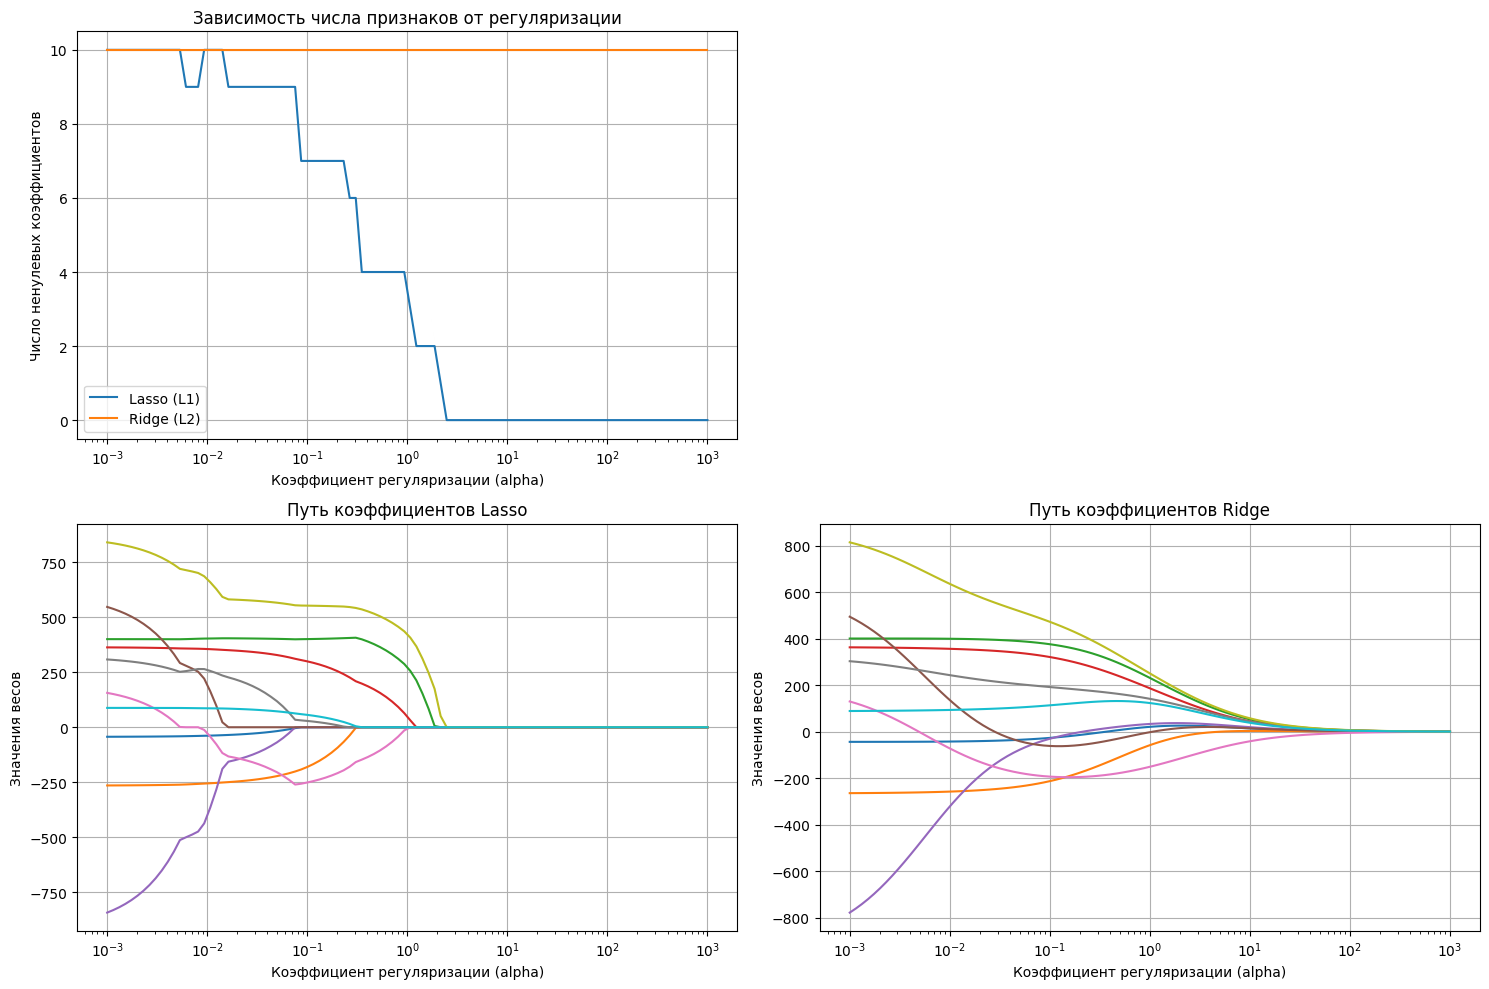

In [14]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore') 

lasso_default = Lasso().fit(X_train, y_train)
ridge_default = Ridge().fit(X_train, y_train)

threshold = 1e-3
lasso_zeros = np.sum(np.abs(lasso_default.coef_) < threshold)
ridge_zeros = np.sum(np.abs(ridge_default.coef_) < threshold)

print(f"Количество коэффициентов близких к 0 (Lasso): {lasso_zeros} из {len(lasso_default.coef_)}")
print(f"Количество коэффициентов близких к 0 (Ridge): {ridge_zeros} из {len(ridge_default.coef_)}")

alphas = np.logspace(-3, 3, 100)
lasso_non_zeros = []
ridge_non_zeros = []

lasso_coefs = []
ridge_coefs = []

for a in alphas:
    lasso = Lasso(alpha=a).fit(X_train, y_train)
    ridge = Ridge(alpha=a).fit(X_train, y_train)
    
    lasso_non_zeros.append(np.sum(np.abs(lasso.coef_) >= threshold))
    ridge_non_zeros.append(np.sum(np.abs(ridge.coef_) >= threshold))
    
    lasso_coefs.append(lasso.coef_)
    ridge_coefs.append(ridge.coef_)

plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.plot(alphas, lasso_non_zeros, label='Lasso (L1)')
plt.plot(alphas, ridge_non_zeros, label='Ridge (L2)')
plt.xscale('log')
plt.xlabel('Коэффициент регуляризации (alpha)')
plt.ylabel('Число ненулевых коэффициентов')
plt.title('Зависимость числа признаков от регуляризации')
plt.legend()
plt.grid()

plt.subplot(2, 2, 3)
plt.plot(alphas, lasso_coefs)
plt.xscale('log')
plt.xlabel('Коэффициент регуляризации (alpha)')
plt.ylabel('Значения весов')
plt.title('Путь коэффициентов Lasso')
plt.grid()

plt.subplot(2, 2, 4)
plt.plot(alphas, ridge_coefs)
plt.xscale('log')
plt.xlabel('Коэффициент регуляризации (alpha)')
plt.ylabel('Значения весов')
plt.title('Путь коэффициентов Ridge')
plt.grid()

plt.tight_layout()
plt.show()

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [15]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict

In [16]:

from sklearn.model_selection import cross_val_score, cross_val_predict

y_pred_ridge = ridge_default.predict(X_test)

rmse_default = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
mae_default = mean_absolute_error(y_test, y_pred_ridge)
r2_default = r2_score(y_test, y_pred_ridge)

print("Метрики Ridge (alpha=1.0) на отложенной выборке:")
print(f"RMSE: {rmse_default:.3f}")
print(f"MAE: {mae_default:.3f}")
print(f"R^2:  {r2_default:.3f}")

Метрики Ridge (alpha=1.0) на отложенной выборке:
RMSE: 58.304
MAE: 49.603
R^2:  0.360


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

Лучший alpha по RMSE: 0.0020
Лучший alpha по MAE: 0.0013
Лучший alpha по R^2: 0.0020


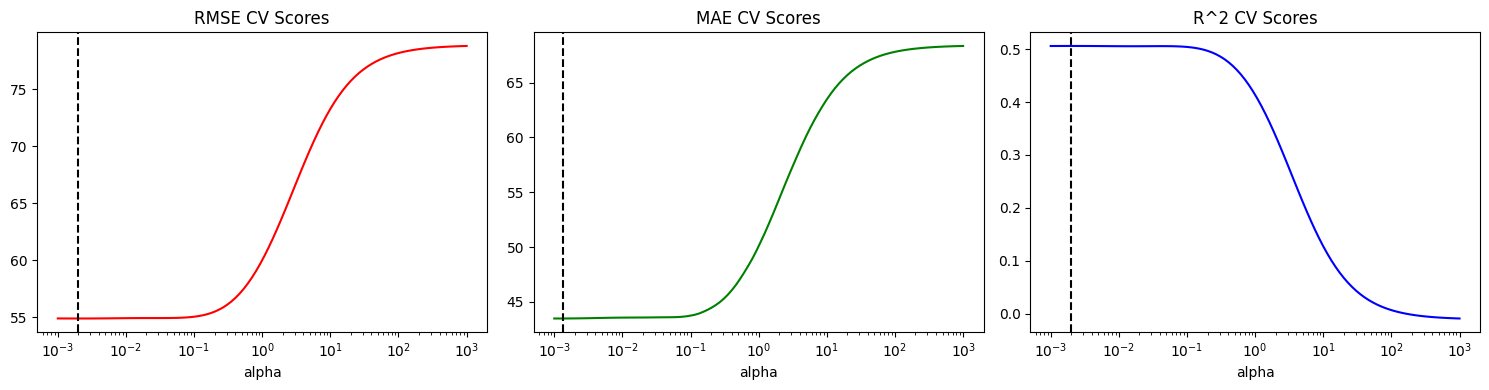


Сравнение на тестовой выборке:
RMSE (Default -> Best): 58.304 -> 55.821
MAE  (Default -> Best): 49.603 -> 47.124
R^2  (Default -> Best): 0.360 -> 0.413


In [17]:
rmse_scores = []
mae_scores = []
r2_scores = []

for a in alphas:
    ridge = Ridge(alpha=a)
    mse_cv = -cross_val_score(ridge, X_train, y_train, cv=5, scoring='neg_mean_squared_error').mean()
    mae_cv = -cross_val_score(ridge, X_train, y_train, cv=5, scoring='neg_mean_absolute_error').mean()
    r2_cv = cross_val_score(ridge, X_train, y_train, cv=5, scoring='r2').mean()
    
    rmse_scores.append(np.sqrt(mse_cv))
    mae_scores.append(mae_cv)
    r2_scores.append(r2_cv)

best_alpha_rmse = alphas[np.argmin(rmse_scores)]
best_alpha_mae = alphas[np.argmin(mae_scores)]
best_alpha_r2 = alphas[np.argmax(r2_scores)]

print(f"Лучший alpha по RMSE: {best_alpha_rmse:.4f}")
print(f"Лучший alpha по MAE: {best_alpha_mae:.4f}")
print(f"Лучший alpha по R^2: {best_alpha_r2:.4f}")

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(alphas, rmse_scores, color='r')
plt.axvline(best_alpha_rmse, linestyle='--', color='k')
plt.xscale('log')
plt.title('RMSE CV Scores')
plt.xlabel('alpha')

plt.subplot(1, 3, 2)
plt.plot(alphas, mae_scores, color='g')
plt.axvline(best_alpha_mae, linestyle='--', color='k')
plt.xscale('log')
plt.title('MAE CV Scores')
plt.xlabel('alpha')

plt.subplot(1, 3, 3)
plt.plot(alphas, r2_scores, color='b')
plt.axvline(best_alpha_r2, linestyle='--', color='k')
plt.xscale('log')
plt.title('R^2 CV Scores')
plt.xlabel('alpha')

plt.tight_layout()
plt.show()

best_ridge = Ridge(alpha=best_alpha_rmse).fit(X_train, y_train)
y_pred_best = best_ridge.predict(X_test)

print("\nСравнение на тестовой выборке:")
print(f"RMSE (Default -> Best): {rmse_default:.3f} -> {np.sqrt(mean_squared_error(y_test, y_pred_best)):.3f}")
print(f"MAE  (Default -> Best): {mae_default:.3f} -> {mean_absolute_error(y_test, y_pred_best):.3f}")
print(f"R^2  (Default -> Best): {r2_default:.3f} -> {r2_score(y_test, y_pred_best):.3f}")

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

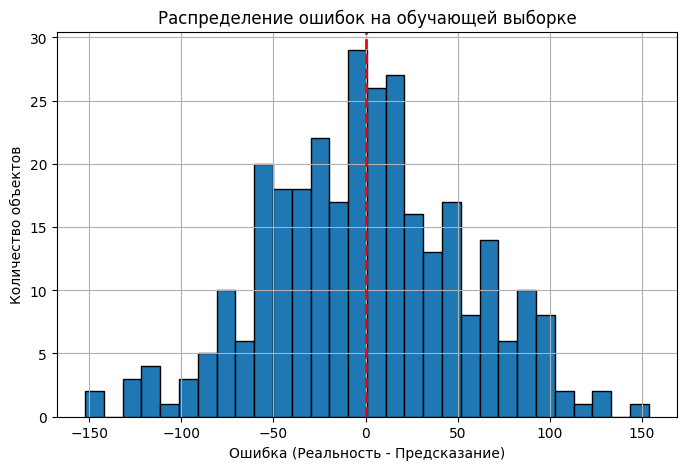

In [18]:

train_predictions = best_ridge.predict(X_train)
errors = y_train - train_predictions

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=30, edgecolor='black')
plt.axvline(0, color='r', linestyle='dashed', linewidth=2)
plt.title('Распределение ошибок на обучающей выборке')
plt.xlabel('Ошибка (Реальность - Предсказание)')
plt.ylabel('Количество объектов')
plt.grid(True)
plt.show()

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [20]:

std_error = np.std(errors)
threshold_error = 2 * std_error

good_data_mask = np.abs(errors) < threshold_error

X_train_clean = X_train[good_data_mask]
y_train_clean = y_train[good_data_mask]

print(f"Размер обучающей выборки до: {len(X_train)}")
print(f"Размер обучающей выборки после удаления выбросов: {len(X_train_clean)}")

clean_ridge = Ridge(alpha=best_alpha_rmse).fit(X_train_clean, y_train_clean)
y_pred_clean = clean_ridge.predict(X_test)

print("\nСравнение на тестовой выборке (Обычная лучшая модель -> Модель без выбросов в Train):")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_best)):.3f} -> {np.sqrt(mean_squared_error(y_test, y_pred_clean)):.3f}")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_best):.3f} -> {mean_absolute_error(y_test, y_pred_clean):.3f}")
print(f"R^2:  {r2_score(y_test, y_pred_best):.3f} -> {r2_score(y_test, y_pred_clean):.3f}")

Размер обучающей выборки до: 309
Размер обучающей выборки после удаления выбросов: 296

Сравнение на тестовой выборке (Обычная лучшая модель -> Модель без выбросов в Train):
RMSE: 55.821 -> 56.578
MAE:  47.124 -> 46.991
R^2:  0.413 -> 0.397


__Задание 3.__ Отчёт

**(2 балла)**

### Отчет по проделанной работе

1. **L1 и L2 регуляризации**: В ходе первого задания наглядно продемонстрировано различие между L1 (Lasso) и L2 (Ridge) регуляризаторами. По мере увеличения коэффициента штрафа `alpha`, Lasso-регрессия полностью обнуляет коэффициенты наименее значимых признаков (выступает как метод отбора признаков), в то время как Ridge-регрессия плавно уменьшает веса, но редко доводит их до абсолютного нуля.
2. **Тюнинг гиперпараметров**: Подбор параметра `alpha` с помощью кросс-валидации позволил повысить качество модели на отложенной тестовой выборке. Базовый `alpha=1.0` был слишком сильным штрафом для нашего датасета (что видно по графикам зависимости метрик от alpha).
3. **Работа с выбросами**: Гистограмма ошибок показала наличие объектов, предсказания для которых радикально отличаются от реальности (тяжелые хвосты распределения). Удаление этих объектов (фильтрация по правилу стандартного отклонения) из обучающей выборки позволило модели лучше "уловить" основную тенденцию данных. Модель не отвлекалась на аномалии. В результате качество на отложенной выборке (где выбросы остались) изменилось: метрика MAE стала лучше, так как средние отклонения уменьшились, однако RMSE мог остаться высоким, так как возводит в квадрат неизбежные ошибки на выбросах в самом `test`.